# 05 - Final results: XGBoost vs GCN vs GraphSAGE

Reads everything saved by `04_gnn.ipynb` and produces the final, report-ready comparison:

1. Model selection on the **validation** set (never on test)
2. Test metrics with bootstrap 95% confidence intervals, and paired differences vs XGBoost
3. ROC / PR curves, confusion matrices, threshold sensitivity
4. Analyst "alert budget" view (what do we catch if we only review the top k% riskiest wallets?)
5. Where the graph helps: performance by wallet degree, and which wallets each model catches or misses
6. Training curves and XGBoost feature importance
7. Exports for the dashboard: `final_results.csv`, `final_summary.md`, `best_model.json`

**Requires:** `04_gnn.ipynb` run to completion (it writes the `gnn_*` files in `../outputs/results/`).

# Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from xgboost import XGBClassifier

SEED = 42
N_BOOT = 500          # bootstrap resamples (~1-2 min on the full test set; lower it for a quick run)
FEATURES = [          # same order as in 04_gnn.ipynb
    "in_degree", "out_degree", "total_degree", "degree_centrality",
    "num_predecessors", "num_successors", "num_neighbors",
]

RESULTS_PATH = Path("../outputs/results")
MODEL_PATH = Path("../outputs/models")
FIGURE_PATH = Path("../outputs/plots")
for p in (RESULTS_PATH, FIGURE_PATH):
    p.mkdir(parents=True, exist_ok=True)

MODEL_COLS = {"XGBoost": "prob_xgboost", "GCN": "prob_gcn", "GraphSAGE": "prob_graphsage"}
COLORS = {"XGBoost": "#d95f02", "GCN": "#1b9e77", "GraphSAGE": "#7570b3"}
ARTIFACTS = {
    "XGBoost": MODEL_PATH / "xgb_baseline_gnn_split.json",
    "GCN": MODEL_PATH / "best_gcn_model.pt",
    "GraphSAGE": MODEL_PATH / "best_graphsage_model.pt",
}

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

# Load results from notebook 04

In [2]:
for f in ["gnn_model_comparison.csv", "gnn_test_predictions.csv"]:
    if not (RESULTS_PATH / f).exists():
        raise FileNotFoundError(f"{RESULTS_PATH / f} not found - run 04_gnn.ipynb to completion first.")

comparison = pd.read_csv(RESULTS_PATH / "gnn_model_comparison.csv")
test_df = pd.read_csv(RESULTS_PATH / "gnn_test_predictions.csv")

y_test = test_df["y_true"].to_numpy()
probs = {m: test_df[c].to_numpy() for m, c in MODEL_COLS.items()}
thr = comparison.set_index("Model")["Threshold"].to_dict()   # chosen on validation in 04

assert set(MODEL_COLS) <= set(thr), "gnn_model_comparison.csv is missing a model"
assert set(np.unique(y_test)) <= {0, 1}

n_test, n_pos = len(y_test), int(y_test.sum())
print(f"Test wallets: {n_test:,} | illicit: {n_pos:,} ({n_pos / n_test:.2%})")
print("Thresholds (picked on validation):", {m: round(t, 4) for m, t in thr.items()})

Test wallets: 39,804 | illicit: 2,140 (5.38%)
Thresholds (picked on validation): {'GraphSAGE': 0.8217, 'GCN': 0.8188, 'XGBoost': 0.9017}


# 1. Model selection (validation set)

The "best" model is chosen on **validation** PR-AUC. Picking it from test scores would leak the test set into the decision.

In [3]:
val_path = RESULTS_PATH / "gnn_val_predictions.csv"
if val_path.exists():
    val_df = pd.read_csv(val_path)
    y_val = val_df["y_true"].to_numpy()
    val_pr = pd.Series({m: average_precision_score(y_val, val_df[c]) for m, c in MODEL_COLS.items()})
    val_roc = pd.Series({m: roc_auc_score(y_val, val_df[c]) for m, c in MODEL_COLS.items()})
    selection = pd.DataFrame({"Val PR-AUC": val_pr, "Val ROC-AUC": val_roc}).sort_values("Val PR-AUC", ascending=False)
    best_model = selection.index[0]
    display(selection)
    print(f"Selected on validation PR-AUC: {best_model}")
else:
    val_pr = pd.Series(dtype=float)
    best_model = comparison.sort_values("PR-AUC", ascending=False)["Model"].iloc[0]
    print("gnn_val_predictions.csv not found (re-run 04). Falling back to TEST PR-AUC for the pick - treat it as indicative only.")
    print("Best model:", best_model)

gnn_val_predictions.csv not found (re-run 04). Falling back to TEST PR-AUC for the pick - treat it as indicative only.
Best model: GraphSAGE


# 2. Test metrics with 95% confidence intervals

Bootstrap over test wallets. The same resamples are used for every model, so differences between models are **paired**: a gap only counts if it survives resampling.

In [4]:
def bootstrap_metrics(y, probs, thr, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    n, rows = len(y), []
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        if yb.sum() in (0, n):
            continue
        for m, p in probs.items():
            pb = p[idx]
            rows.append({
                "boot": b, "Model": m,
                "ROC-AUC": roc_auc_score(yb, pb),
                "PR-AUC": average_precision_score(yb, pb),
                "Illicit F1": f1_score(yb, pb >= thr[m], zero_division=0),
            })
    return pd.DataFrame(rows)


boot = bootstrap_metrics(y_test, probs, thr)
print(f"{boot['boot'].nunique()} bootstrap resamples")

point = comparison.set_index("Model")
rows = []
for m in MODEL_COLS:
    row = {"Model": m}
    for metric in ["ROC-AUC", "PR-AUC", "Illicit F1"]:
        v = boot.loc[boot["Model"] == m, metric]
        row[metric] = point.loc[m, metric]
        row[f"{metric} lo"], row[f"{metric} hi"] = v.quantile(0.025), v.quantile(0.975)
    row["Illicit Precision"] = point.loc[m, "Illicit Precision"]
    row["Illicit Recall"] = point.loc[m, "Illicit Recall"]
    row["Threshold"] = thr[m]
    row["Val PR-AUC"] = val_pr.get(m, np.nan)
    rows.append(row)

final_results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)

pretty = final_results[["Model"]].copy()
for metric in ["ROC-AUC", "PR-AUC", "Illicit F1"]:
    pretty[metric] = [f"{r[metric]:.3f} [{r[metric + ' lo']:.3f}, {r[metric + ' hi']:.3f}]" for _, r in final_results.iterrows()]
pretty["Illicit Precision"] = final_results["Illicit Precision"].map("{:.3f}".format)
pretty["Illicit Recall"] = final_results["Illicit Recall"].map("{:.3f}".format)
display(pretty)

500 bootstrap resamples


,Model,ROC-AUC,PR-AUC,Illicit F1,Illicit Precision,Illicit Recall
0,GraphSAGE,"0.974 [0.972, 0.977]","0.794 [0.778, 0.809]","0.726 [0.707, 0.739]",0.764,0.693
1,GCN,"0.921 [0.916, 0.926]","0.471 [0.448, 0.494]","0.479 [0.458, 0.497]",0.538,0.432
2,XGBoost,"0.878 [0.869, 0.886]","0.460 [0.435, 0.482]","0.582 [0.562, 0.599]",0.674,0.512


In [5]:
# Paired differences: is the gap real, or resampling noise?
piv = {metric: boot.pivot(index="boot", columns="Model", values=metric)
       for metric in ["PR-AUC", "ROC-AUC", "Illicit F1"]}

pairs = [("GCN", "XGBoost"), ("GraphSAGE", "XGBoost"), ("GraphSAGE", "GCN")]
diff_rows = []
for a, b in pairs:
    for metric, t in piv.items():
        d = t[a] - t[b]
        diff_rows.append({
            "Comparison": f"{a} - {b}", "Metric": metric,
            "Mean difference": d.mean(),
            "95% CI low": d.quantile(0.025), "95% CI high": d.quantile(0.975),
            f"P({a} better)": (d > 0).mean(),
        })
paired = pd.DataFrame(diff_rows)
display(paired)

,Comparison,Metric,Mean difference,95% CI low,95% CI high,P(GCN better),P(GraphSAGE better)
0,GCN - XGBoost,PR-AUC,0.0121,-0.0114,0.0347,0.8500,NaN
1,GCN - XGBoost,ROC-AUC,0.0430,0.0347,0.0519,1.0000,NaN
2,GCN - XGBoost,Illicit F1,-0.1028,-0.1217,-0.0835,0.0000,NaN
3,GraphSAGE - XGBoost,PR-AUC,0.3343,0.3156,0.3547,NaN,1.0000
4,GraphSAGE - XGBoost,ROC-AUC,0.0960,0.0891,0.1035,NaN,1.0000
5,GraphSAGE - XGBoost,Illicit F1,0.1416,0.1236,0.1590,NaN,1.0000
6,GraphSAGE - GCN,PR-AUC,0.3222,0.3005,0.3439,NaN,1.0000
7,GraphSAGE - GCN,ROC-AUC,0.0530,0.0487,0.0575,NaN,1.0000
8,GraphSAGE - GCN,Illicit F1,0.2444,0.2260,0.2649,NaN,1.0000


# 3. ROC and Precision-Recall curves

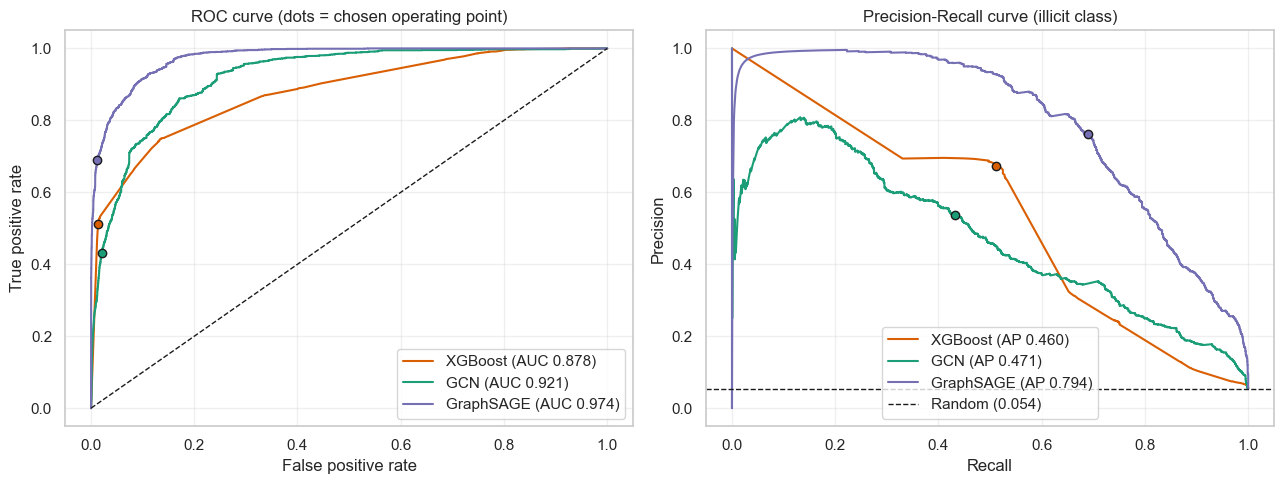

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
neg = n_test - n_pos

for m, p in probs.items():
    pred = p >= thr[m]
    tp = int((pred & (y_test == 1)).sum())
    fp = int((pred & (y_test == 0)).sum())

    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=COLORS[m], label=f"{m} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[0].scatter(fp / neg, tp / n_pos, color=COLORS[m], edgecolor="k", zorder=5)

    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=COLORS[m], label=f"{m} (AP {average_precision_score(y_test, p):.3f})")
    axes[1].scatter(tp / n_pos, tp / max(tp + fp, 1), color=COLORS[m], edgecolor="k", zorder=5)

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve (dots = chosen operating point)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(n_pos / n_test, color="k", ls="--", lw=1, label=f"Random ({n_pos / n_test:.3f})")
axes[1].set(title="Precision-Recall curve (illicit class)", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_PATH / "results_roc_pr_curves.png", dpi=300)
plt.show()

# 4. Confusion matrices at the chosen thresholds

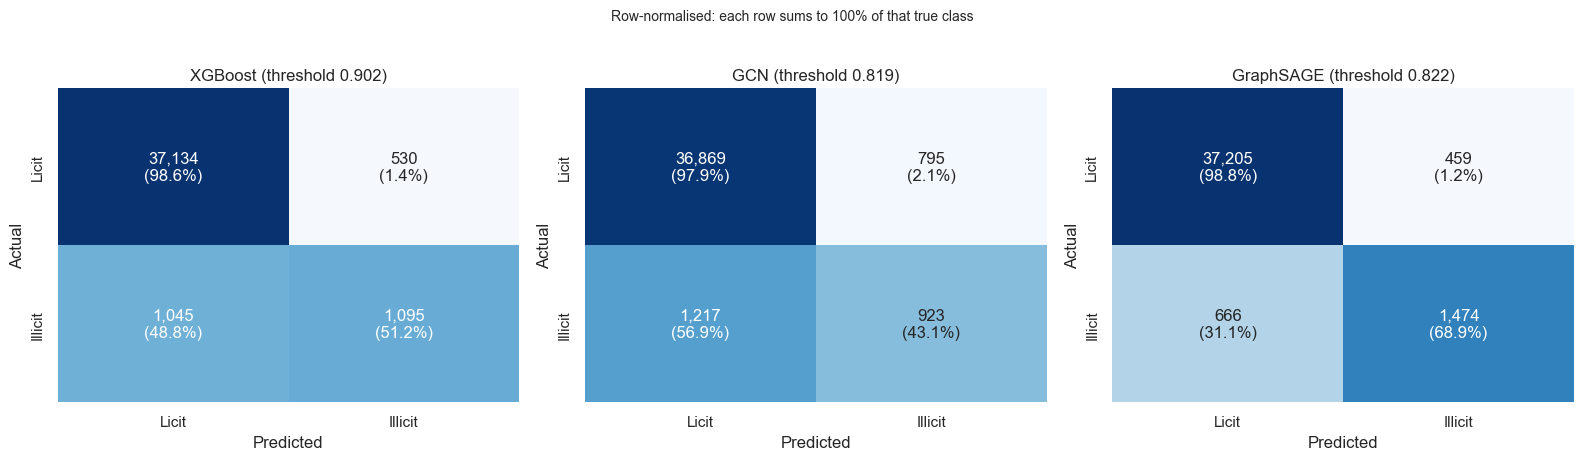

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, probs):
    pred = (probs[m] >= thr[m]).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Licit", "Illicit"], yticklabels=["Licit", "Illicit"])
    ax.set(title=f"{m} (threshold {thr[m]:.3f})", xlabel="Predicted", ylabel="Actual")
plt.suptitle("Row-normalised: each row sums to 100% of that true class", y=1.02, fontsize=10)
plt.tight_layout()
plt.savefig(FIGURE_PATH / "results_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Threshold sensitivity

How fragile is each model's operating point? The dashed line is the threshold picked on validation.

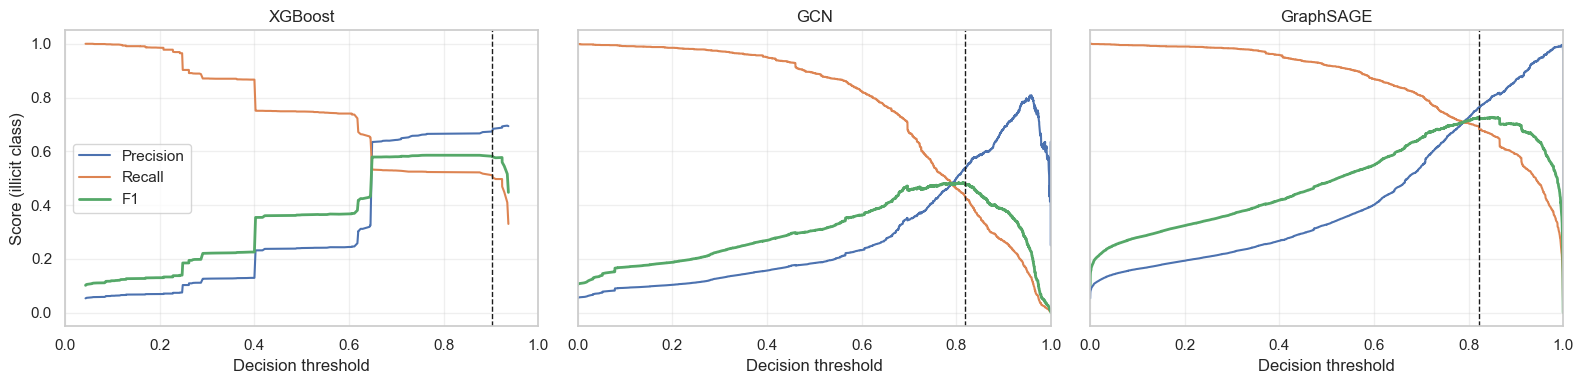

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (m, p) in zip(axes, probs.items()):
    prec, rec, t = precision_recall_curve(y_test, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    ax.plot(t, prec[:-1], label="Precision")
    ax.plot(t, rec[:-1], label="Recall")
    ax.plot(t, f1, label="F1", lw=2)
    ax.axvline(thr[m], color="k", ls="--", lw=1)
    ax.set(title=m, xlabel="Decision threshold", xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Score (illicit class)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURE_PATH / "results_threshold_sensitivity.png", dpi=300)
plt.show()

# 6. Alert budget: review only the top k% riskiest wallets

Investigators cannot review every wallet. This ranks test wallets by each model's score and asks how many illicit wallets sit in the top k%. It does not depend on any threshold.

In [9]:
FRACTIONS = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.10]


def top_k_table(y, probs, fractions=FRACTIONS):
    n, pos, rows = len(y), int(y.sum()), []
    for m, p in probs.items():
        ranked = y[np.argsort(-p, kind="stable")]
        hits = np.cumsum(ranked)
        for f in fractions:
            k = max(1, int(round(f * n)))
            rows.append({
                "Model": m, "Reviewed %": f * 100, "Wallets reviewed": k,
                "Precision@k": hits[k - 1] / k,
                "Recall@k": hits[k - 1] / pos,
                "Lift vs random": (hits[k - 1] / k) / (pos / n),
            })
    return pd.DataFrame(rows)


topk = top_k_table(y_test, probs)
display(topk.pivot(index="Reviewed %", columns="Model", values="Recall@k")[list(MODEL_COLS)]
        .style.format("{:.1%}").set_caption("Recall@k: share of all illicit wallets found"))
display(topk.pivot(index="Reviewed %", columns="Model", values="Precision@k")[list(MODEL_COLS)]
        .style.format("{:.1%}").set_caption("Precision@k: share of reviewed wallets that are illicit"))

Model,XGBoost,GCN,GraphSAGE
Reviewed %,,,
0.100000,0.0%,0.9%,1.8%
0.250000,1.7%,2.9%,4.6%
0.500000,5.3%,6.9%,9.2%
1.000000,11.1%,14.7%,18.5%
2.000000,25.4%,25.9%,36.6%
5.000000,54.1%,46.3%,69.7%
10.000000,64.1%,65.6%,84.3%


Model,XGBoost,GCN,GraphSAGE
Reviewed %,,,
0.100000,0.0%,47.5%,95.0%
0.250000,37.0%,62.0%,98.0%
0.500000,56.8%,74.4%,99.0%
1.000000,59.5%,78.9%,99.5%
2.000000,68.2%,69.6%,98.4%
5.000000,58.1%,49.8%,74.9%
10.000000,34.5%,35.3%,45.3%


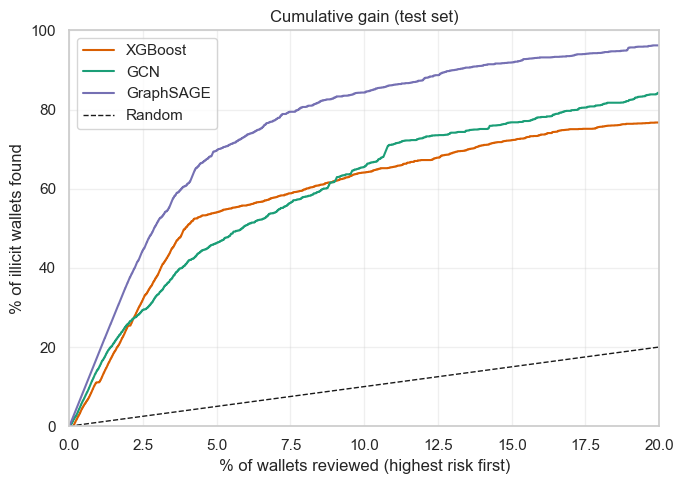

In [10]:
plt.figure(figsize=(7, 5))
for m, p in probs.items():
    ranked = y_test[np.argsort(-p, kind="stable")]
    gain = np.cumsum(ranked) / n_pos
    plt.plot(np.arange(1, n_test + 1) / n_test * 100, gain * 100, color=COLORS[m], label=m)
plt.plot([0, 100], [0, 100], "k--", lw=1, label="Random")
plt.xlim(0, 20)
plt.ylim(0, 100)
plt.xlabel("% of wallets reviewed (highest risk first)")
plt.ylabel("% of illicit wallets found")
plt.title("Cumulative gain (test set)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_PATH / "results_cumulative_gain.png", dpi=300)
plt.show()

# 7. Where does the graph help?

### 7a. Performance by wallet degree
Low-degree wallets have little information in their own features. If message passing helps, it should show up there.

Test wallets without a degree value: 0


,Degree bucket,Wallets,Illicit,XGBoost recall,XGBoost precision,XGBoost PR-AUC,GCN recall,GCN precision,GCN PR-AUC,GraphSAGE recall,GraphSAGE precision,GraphSAGE PR-AUC
0,<=1,11155,388,0.0000,NaN,0.0790,0.0747,0.2900,0.2329,0.6985,0.7021,0.6410
1,2,10603,989,0.7149,0.6938,0.5277,0.5379,0.7710,0.6971,0.7068,0.9408,0.8662
2,3-5,7068,544,0.5772,0.6695,0.4901,0.5000,0.4211,0.4393,0.6912,0.6164,0.7692
3,6-20,7626,197,0.3756,0.5401,0.4256,0.4112,0.3716,0.3622,0.6294,0.6561,0.7456
4,21-100,2907,17,0.0000,NaN,NaN,0.4118,0.1321,NaN,0.1765,0.7500,NaN
5,>100,445,5,0.0000,NaN,NaN,0.4000,0.1818,NaN,0.2000,1.0000,NaN


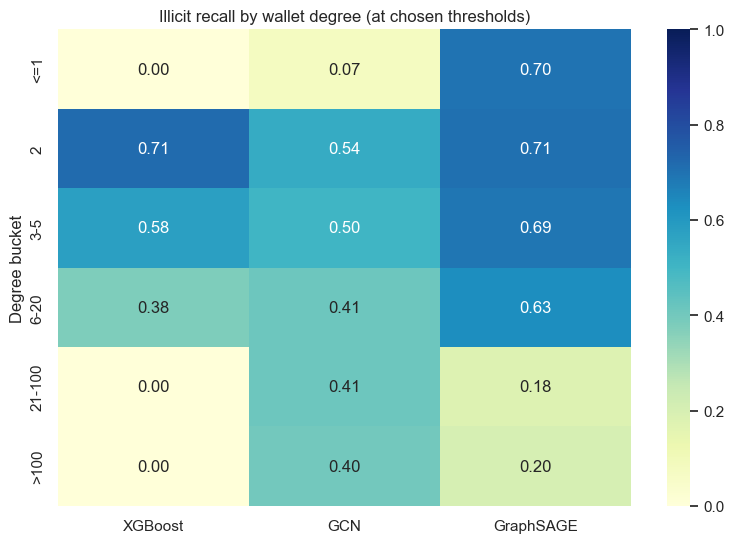

In [11]:
feat_path = RESULTS_PATH / "wallet_graph_features_with_labels.csv"
degree_table = None

if feat_path.exists():
    feats = pd.read_csv(feat_path, usecols=["address", "total_degree"])
    d = test_df.merge(feats, on="address", how="left")
    print("Test wallets without a degree value:", int(d["total_degree"].isna().sum()))

    bins = [-1, 1, 2, 5, 20, 100, np.inf]
    labels = ["<=1", "2", "3-5", "6-20", "21-100", ">100"]
    d["Degree bucket"] = pd.cut(d["total_degree"], bins=bins, labels=labels)

    rows = []
    for bucket, g in d.groupby("Degree bucket", observed=True):
        yb = g["y_true"].to_numpy()
        row = {"Degree bucket": bucket, "Wallets": len(g), "Illicit": int(yb.sum())}
        for m, c in MODEL_COLS.items():
            pb = g[c].to_numpy()
            pred = pb >= thr[m]
            row[f"{m} recall"] = recall_score(yb, pred, zero_division=0) if yb.sum() > 0 else np.nan
            row[f"{m} precision"] = precision_score(yb, pred, zero_division=0) if pred.sum() > 0 else np.nan
            ok = yb.sum() >= 20 and (len(yb) - yb.sum()) >= 20          # AUC is unstable on tiny buckets
            row[f"{m} PR-AUC"] = average_precision_score(yb, pb) if ok else np.nan
        rows.append(row)
    degree_table = pd.DataFrame(rows)
    display(degree_table)

    recall_cols = [f"{m} recall" for m in MODEL_COLS]
    plt.figure(figsize=(8, 0.6 * len(degree_table) + 2))
    sns.heatmap(degree_table.set_index("Degree bucket")[recall_cols].rename(columns=lambda c: c.replace(" recall", "")),
                annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
    plt.title("Illicit recall by wallet degree (at chosen thresholds)")
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / "results_recall_by_degree.png", dpi=300)
    plt.show()
else:
    print("wallet_graph_features_with_labels.csv not found - skipping degree analysis.")

### 7b. Which wallets does each GNN catch or miss compared with XGBoost?
At the chosen thresholds, split the illicit wallets (and the false alarms) by which model flagged them.

In [12]:
rows = []
ill, lic = y_test == 1, y_test == 0
flag_x = probs["XGBoost"] >= thr["XGBoost"]

for g in ["GCN", "GraphSAGE"]:
    flag_g = probs[g] >= thr[g]
    rows.append({
        "GNN": g,
        "Illicit: both catch": int((flag_x & flag_g & ill).sum()),
        "Illicit: only XGBoost": int((flag_x & ~flag_g & ill).sum()),
        "Illicit: only GNN": int((~flag_x & flag_g & ill).sum()),
        "Illicit: neither": int((~flag_x & ~flag_g & ill).sum()),
        "False alarms: both": int((flag_x & flag_g & lic).sum()),
        "False alarms: only XGBoost": int((flag_x & ~flag_g & lic).sum()),
        "False alarms: only GNN": int((~flag_x & flag_g & lic).sum()),
    })
overlap = pd.DataFrame(rows)
display(overlap)

,GNN,Illicit: both catch,Illicit: only XGBoost,Illicit: only GNN,Illicit: neither,False alarms: both,False alarms: only XGBoost,False alarms: only GNN
0,GCN,737,358,186,859,23,507,772
1,GraphSAGE,1046,49,428,617,38,492,421


# 8. Training curves (GCN vs GraphSAGE)

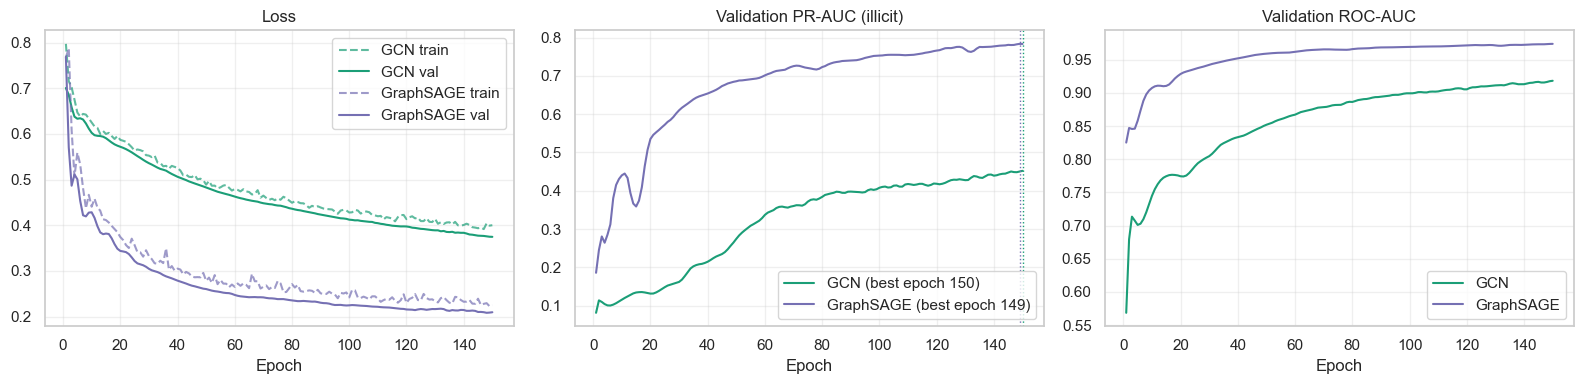

In [13]:
hist_files = {"GCN": RESULTS_PATH / "gnn_history_gcn.csv", "GraphSAGE": RESULTS_PATH / "gnn_history_graphsage.csv"}
histories = {m: pd.read_csv(f) for m, f in hist_files.items() if f.exists()}

if histories:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for m, h in histories.items():
        best_ep = int(h.loc[h["val_pr_auc"].idxmax(), "epoch"])
        axes[0].plot(h["epoch"], h["train_loss"], color=COLORS[m], ls="--", alpha=0.7, label=f"{m} train")
        axes[0].plot(h["epoch"], h["val_loss"], color=COLORS[m], label=f"{m} val")
        axes[1].plot(h["epoch"], h["val_pr_auc"], color=COLORS[m], label=f"{m} (best epoch {best_ep})")
        axes[2].plot(h["epoch"], h["val_roc_auc"], color=COLORS[m], label=m)
        axes[1].axvline(best_ep, color=COLORS[m], ls=":", lw=1)
    axes[0].set(title="Loss", xlabel="Epoch")
    axes[1].set(title="Validation PR-AUC (illicit)", xlabel="Epoch")
    axes[2].set(title="Validation ROC-AUC", xlabel="Epoch")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / "results_training_curves.png", dpi=300)
    plt.show()
else:
    print("No GNN history files found.")

# 9. XGBoost feature importance

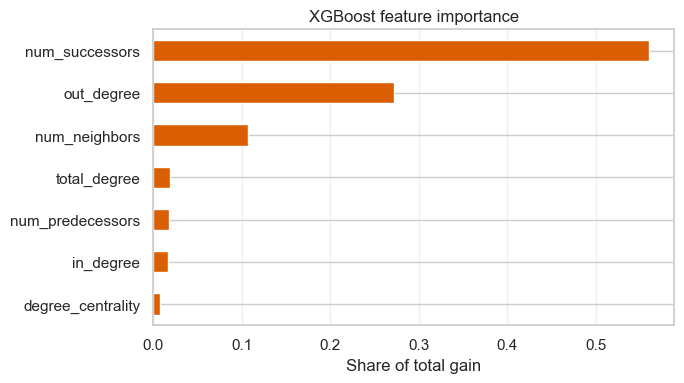

In [14]:
xgb_path = ARTIFACTS["XGBoost"]
importance = None

if xgb_path.exists():
    clf = XGBClassifier()
    clf.load_model(xgb_path)
    raw = clf.get_booster().get_score(importance_type="gain")      # features never used are absent

    def feature_name(key):
        if key in FEATURES:
            return key
        if key.startswith("f") and key[1:].isdigit() and int(key[1:]) < len(FEATURES):
            return FEATURES[int(key[1:])]
        return key

    gain = pd.Series({feature_name(k): v for k, v in raw.items()}).reindex(FEATURES).fillna(0.0)
    importance = (gain / gain.sum()).sort_values()

    plt.figure(figsize=(7, 4))
    importance.plot(kind="barh", color=COLORS["XGBoost"])
    plt.xlabel("Share of total gain")
    plt.title("XGBoost feature importance")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / "results_xgb_feature_importance.png", dpi=300)
    plt.show()
else:
    print(f"{xgb_path} not found - skipping.")

# 10. Reference: results reported by `03_train_models.ipynb`

These come from notebook 03's own run. Treat them as context only: 03 may use a different split from the one used for the comparison above, so the numbers are not directly comparable.

In [15]:
ref_path = RESULTS_PATH / "model_comparison.csv"
if ref_path.exists():
    display(pd.read_csv(ref_path))
else:
    print("model_comparison.csv from notebook 03 not found - skipping.")

,Model,Accuracy,Illicit Precision,Illicit Recall,Illicit F1,ROC-AUC,PR-AUC
0,XGBoost,0.9604,0.6701,0.5173,0.5839,0.8778,0.4622
1,Random Forest,0.9607,0.6780,0.5117,0.5832,0.8713,0.4580
2,Logistic Regression,0.6412,0.0785,0.5280,0.1366,0.5482,0.0622


# 11. Export for the dashboard and the report

In [16]:
final_results.to_csv(RESULTS_PATH / "final_results.csv", index=False)
paired.to_csv(RESULTS_PATH / "final_paired_differences.csv", index=False)
topk.to_csv(RESULTS_PATH / "final_topk_alert_budget.csv", index=False)
if degree_table is not None:
    degree_table.to_csv(RESULTS_PATH / "final_degree_breakdown.csv", index=False)

best_row = final_results.set_index("Model").loc[best_model]
best_info = {
    "selected_by": "validation PR-AUC" if len(val_pr) else "test PR-AUC (validation predictions missing)",
    "best_model": best_model,
    "threshold": float(thr[best_model]),
    "artifact": str(ARTIFACTS[best_model]),
    "test_metrics": {k: float(best_row[k]) for k in ["ROC-AUC", "PR-AUC", "Illicit Precision", "Illicit Recall", "Illicit F1"]},
    "test_wallets": int(n_test),
    "test_illicit": int(n_pos),
}
with open(RESULTS_PATH / "best_model.json", "w") as f:
    json.dump(best_info, f, indent=2)
print(json.dumps(best_info, indent=2))

{
  "selected_by": "test PR-AUC (validation predictions missing)",
  "best_model": "GraphSAGE",
  "threshold": 0.821734607219696,
  "artifact": "..\\outputs\\models\\best_graphsage_model.pt",
  "test_metrics": {
    "ROC-AUC": 0.9742121681925376,
    "PR-AUC": 0.7941836484090091,
    "Illicit Precision": 0.7635239567233385,
    "Illicit Recall": 0.6925233644859813,
    "Illicit F1": 0.7262925753491791
  },
  "test_wallets": 39804,
  "test_illicit": 2140
}


In [17]:
def md_table(df, cols):
    head = "| " + " | ".join(cols) + " |\n|" + "|".join(["---"] * len(cols)) + "|\n"
    return head + "\n".join("| " + " | ".join(str(r[c]) for c in cols) + " |" for _, r in df.iterrows())


def fmt_ci(r, metric):
    return f"{r[metric]:.3f} [{r[metric + ' lo']:.3f}, {r[metric + ' hi']:.3f}]"


table = pd.DataFrame({
    "Model": final_results["Model"],
    "PR-AUC [95% CI]": [fmt_ci(r, "PR-AUC") for _, r in final_results.iterrows()],
    "ROC-AUC [95% CI]": [fmt_ci(r, "ROC-AUC") for _, r in final_results.iterrows()],
    "Illicit precision": final_results["Illicit Precision"].map("{:.3f}".format),
    "Illicit recall": final_results["Illicit Recall"].map("{:.3f}".format),
    "Illicit F1 [95% CI]": [fmt_ci(r, "Illicit F1") for _, r in final_results.iterrows()],
})

lines = [
    "# Wallet illicit-activity detection: final results",
    "",
    f"Test set: {n_test:,} labeled wallets, {n_pos:,} illicit ({n_pos / n_test:.2%}). "
    f"Model selected on validation PR-AUC: **{best_model}**.",
    "",
    md_table(table, list(table.columns)),
    "",
    "## Paired differences (bootstrap, 95% CI)",
    "",
]
for _, r in paired[paired["Metric"] == "PR-AUC"].iterrows():
    better = r["Comparison"].split(" - ")[0]
    lines.append(
        f"- {r['Comparison']} PR-AUC: {r['Mean difference']:+.3f} "
        f"[{r['95% CI low']:+.3f}, {r['95% CI high']:+.3f}]; "
        f"{better} better in {r[f'P({better} better)']:.1%} of resamples"
    )

k1 = topk[np.isclose(topk["Reviewed %"], 1.0)].set_index("Model")
lines += ["", "## Alert budget (review the top 1% highest-risk wallets)", ""]
for m in MODEL_COLS:
    lines.append(f"- {m}: finds {k1.loc[m, 'Recall@k']:.1%} of illicit wallets "
                 f"at {k1.loc[m, 'Precision@k']:.1%} precision ({k1.loc[m, 'Lift vs random']:.1f}x random)")

lines += ["", "Thresholds were chosen on the validation set (max illicit F1) and applied unchanged to the test set."]
summary = "\n".join(lines)

(RESULTS_PATH / "final_summary.md").write_text(summary, encoding="utf-8")
print(summary)

# Wallet illicit-activity detection: final results

Test set: 39,804 labeled wallets, 2,140 illicit (5.38%). Model selected on validation PR-AUC: **GraphSAGE**.

| Model | PR-AUC [95% CI] | ROC-AUC [95% CI] | Illicit precision | Illicit recall | Illicit F1 [95% CI] |
|---|---|---|---|---|---|
| GraphSAGE | 0.794 [0.778, 0.809] | 0.974 [0.972, 0.977] | 0.764 | 0.693 | 0.726 [0.707, 0.739] |
| GCN | 0.471 [0.448, 0.494] | 0.921 [0.916, 0.926] | 0.538 | 0.432 | 0.479 [0.458, 0.497] |
| XGBoost | 0.460 [0.435, 0.482] | 0.878 [0.869, 0.886] | 0.674 | 0.512 | 0.582 [0.562, 0.599] |

## Paired differences (bootstrap, 95% CI)

- GCN - XGBoost PR-AUC: +0.012 [-0.011, +0.035]; GCN better in 85.0% of resamples
- GraphSAGE - XGBoost PR-AUC: +0.334 [+0.316, +0.355]; GraphSAGE better in 100.0% of resamples
- GraphSAGE - GCN PR-AUC: +0.322 [+0.300, +0.344]; GraphSAGE better in 100.0% of resamples

## Alert budget (review the top 1% highest-risk wallets)

- XGBoost: finds 11.1% of illicit wallets at 5